Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [1]:
# function defs
from importlib import reload

from util import *
import util as u

reload(u)


def typst_table(
    df, diag=True, left="s", right="w", style=lambda x: x, index_title=None
):
    s = df.style.format(precision=3)
    s = style(s)
    string = s.to_typst().replace("\n", "")
    if diag:
        string = string.replace("[]", f"diagbox()[{left}][{right}]")
    elif index_title:
        string = string.replace("[]", f"[{index_title}]")
    display(string)
    display(s)

In [2]:
# | label: info

c = Context("../PowerIDS/classifier/power_csv")

self = Experiment(
    c,
    State.IDLE,
    [Metric.MEAN],
    180,
    10,
    # include=["cosori", "appletv", "tcltv", "toshiba"],
)
print(len(self.devices))
print(c.categories)
print(len(c.data[0].testing))

32
['lights', 'audio', 'camera', 'tv', 'appliance']


AttributeError: 'Context' object has no attribute 'data'

In [ ]:
# graph_confusion_matrix(exp, matrix)
# pp.pprint(list(zip(exp.devices, compute_f1_scores(matrix)))[::-1])
# Get a list of devices that are not correctly classified.
# pp.pprint(
#     {
#         Device: Counter(class_)
#         for Device, class_ in classes.items()
#         if len(Counter(class_).items()) > 1
#     }
# )
# TODO computer f1 score and do graph without those.

# TODO why is LIFX misclassified
# TODO would ordering this by median be easier?

plt.show()
window_sizes = [10, 60, 180, 300, 600]
shifts = [2, 10, 30, 60]

df = pd.DataFrame(
    [
        [
            Experiment(
                c,
                State.IDLE,
                [Metric.MEAN],
                window_size,
                shift,
            ).f1_macro_average
            for window_size in window_sizes
        ]
        for shift in shifts
    ],
    shifts,
    window_sizes,
)

In [ ]:
# TODO fix outlier removal

# window_sizes = [10, 60, 180, 300, 600]
# shifts = [2, 10, 30, 60]
# df_both = pd.DataFrame(
#     [
#         [
#             Experiment(
#                 c,
#                 State.IDLE,
#                 Metric.MEAN_NO_UTLIERS,
#                 window_size,
#                 shift,
#             ).f1_macro_average
#             for window_size in window_sizes
#         ]
#         for shift in shifts
#     ],
#     shifts,
#     window_sizes,
# )

In [ ]:
# | label: results


# typst_table(df, style=lambda style: style.highlight_between(left=0.7))
# typst_table(df_both)

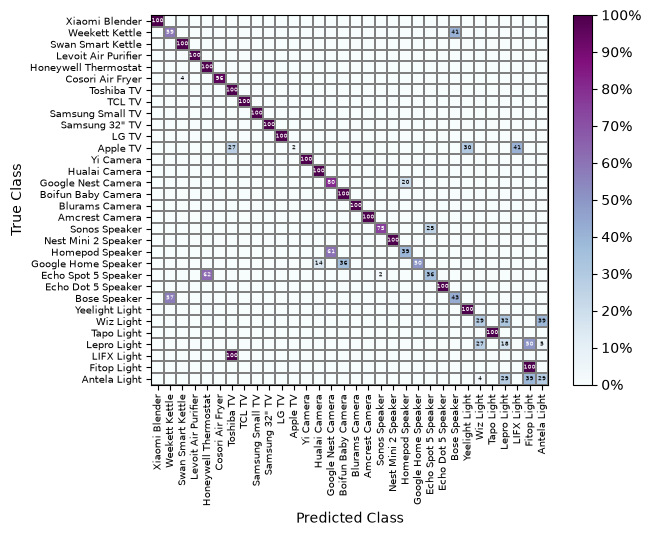

'#table(  columns: 3,  [IoT Device], [Precision], [F1 score],  [Fitop Light], [1.000], [0.691],  [Tapo Light], [1.000], [1.000],  [Yeelight Light], [1.000], [0.868],  [Echo Dot 5 Speaker], [1.000], [1.000],  [Nest Mini 2 Speaker], [1.000], [1.000],  [Amcrest Camera], [1.000], [1.000],  [Blurams Camera], [1.000], [1.000],  [Xiaomi Blender], [1.000], [1.000],  [TCL TV], [1.000], [1.000],  [Toshiba TV], [1.000], [0.612],  [Samsung 32" TV], [1.000], [1.000],  [Samsung Small TV], [1.000], [1.000],  [LG TV], [1.000], [1.000],  [Yi Camera], [1.000], [1.000],  [Hualai Camera], [1.000], [0.933],  [Boifun Baby Camera], [1.000], [0.848],  [Honeywell Thermostat], [1.000], [0.762],  [Swan Smart Kettle], [1.000], [0.982],  [Levoit Air Purifier], [1.000], [1.000],  [Cosori Air Fryer], [0.964], [0.982],  [Google Nest Camera], [0.804], [0.667],  [Sonos Speaker], [0.750], [0.848],  [Weekett Kettle], [0.589], [0.545],  [Google Home Speaker], [0.500], [0.667],  [Bose Speaker], [0.429], [0.466],  [Homepod 

,Precision,F1 score
Fitop Light,1.000,0.691
Tapo Light,1.000,1.000
Yeelight Light,1.000,0.868
Echo Dot 5 Speaker,1.000,1.000
Nest Mini 2 Speaker,1.000,1.000
Amcrest Camera,1.000,1.000
Blurams Camera,1.000,1.000
Xiaomi Blender,1.000,1.000
TCL TV,1.000,1.000
Toshiba TV,1.000,0.612


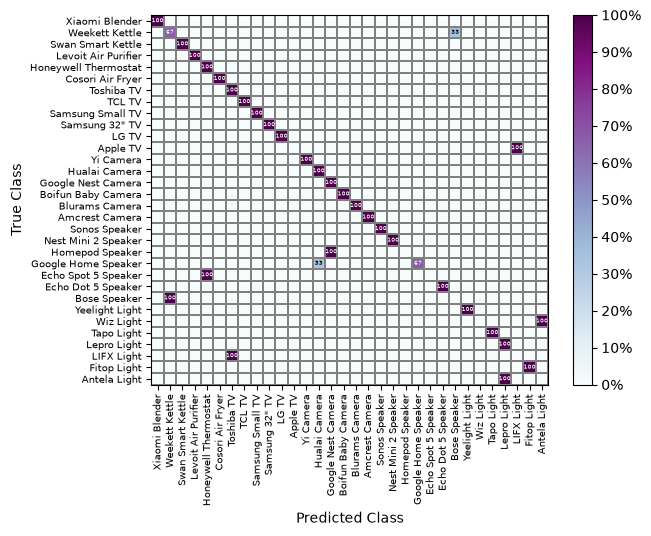

'#table(  columns: 3,  [IoT Device], [Precision], [F1 score],  [Device], [IoT Device], [IoT Device],  [Fitop Light], [1.000], [0.691],  [Tapo Light], [1.000], [1.000],  [Yeelight Light], [1.000], [0.868],  [Echo Dot 5 Speaker], [1.000], [1.000],  [Nest Mini 2 Speaker], [1.000], [1.000],  [Amcrest Camera], [1.000], [1.000],  [Blurams Camera], [1.000], [1.000],  [Xiaomi Blender], [1.000], [1.000],  [TCL TV], [1.000], [1.000],  [Toshiba TV], [1.000], [0.612],  [Samsung 32" TV], [1.000], [1.000],  [Samsung Small TV], [1.000], [1.000],  [LG TV], [1.000], [1.000],  [Yi Camera], [1.000], [1.000],  [Hualai Camera], [1.000], [0.933],  [Boifun Baby Camera], [1.000], [0.848],  [Honeywell Thermostat], [1.000], [0.762],  [Swan Smart Kettle], [1.000], [0.982],  [Levoit Air Purifier], [1.000], [1.000],  [Cosori Air Fryer], [0.964], [0.982],  [Google Nest Camera], [0.804], [0.667],  [Sonos Speaker], [0.750], [0.848],  [Weekett Kettle], [0.589], [0.545],  [Google Home Speaker], [0.500], [0.667],  [Bose

,Precision,F1 score
Device,,
Fitop Light,1.000,0.691
Tapo Light,1.000,1.000
Yeelight Light,1.000,0.868
Echo Dot 5 Speaker,1.000,1.000
Nest Mini 2 Speaker,1.000,1.000
Amcrest Camera,1.000,1.000
Blurams Camera,1.000,1.000
Xiaomi Blender,1.000,1.000
TCL TV,1.000,1.000


'#table(  columns: 2,  [State], [Macro Average F1 score],  [Idle], [0.742],  [Average], [0.834],)'

,Macro Average F1 score
Idle,0.742
Average,0.834


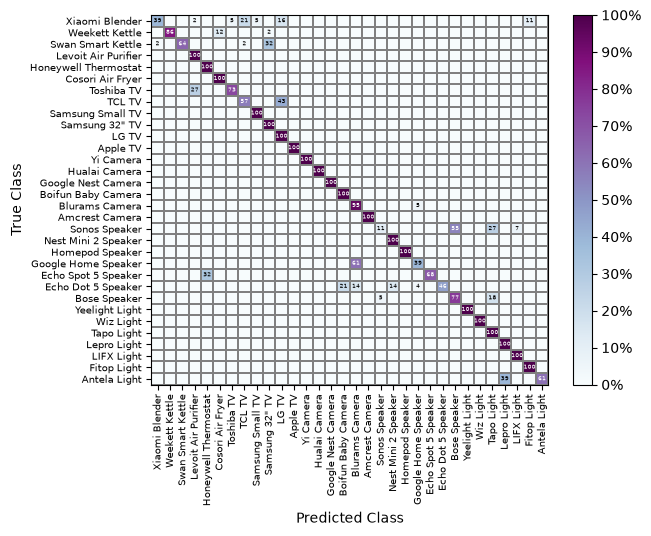

In [ ]:
# | label: confusion matrix
idle = Experiment(
    c,
    State.IDLE,
    [Metric.MEAN],
    180,
    10,
)
graph_confusion_matrix(idle)
plt.show()

typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    pd.DataFrame(
        data={"Precision": idle.precision, "F1 score": idle.f1_scores},
        index=idle.devices,
    ).sort_values(by=["Precision"], ascending=False),
    diag=False,
    index_title="IoT Device",
)

out = Experiment(
    c,
    State.IDLE,
    [Metric.MEAN],
    600,
    60,
)
graph_confusion_matrix(out)
plt.show()

performance = pd.DataFrame(
    data={"Precision": idle.precision, "F1 score": idle.f1_scores}, index=idle.devices
).sort_values(by=["Precision"], ascending=False)
performance.index.name = "Device"
typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    performance,
    diag=False,
    index_title="IoT Device",
)


# display(len([1 for score in all.f1_scores.values() if score > 0.9]))

# # include only devices from above who are not equal to 100
active = Experiment(
    c,
    State.ACTIVE,
    [Metric.MEAN],
    180,
    10,
)
graph_confusion_matrix(active)

typst_table(
    pd.DataFrame(
        data={
            "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average]
        },
        index=["Idle", "Average"],
    ),
    diag=False,
    index_title="State",
)

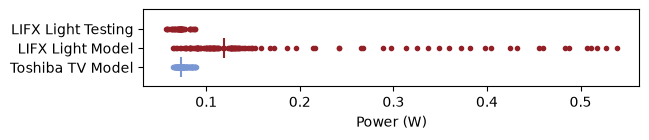

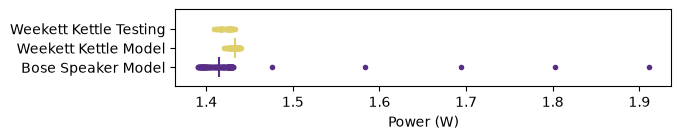

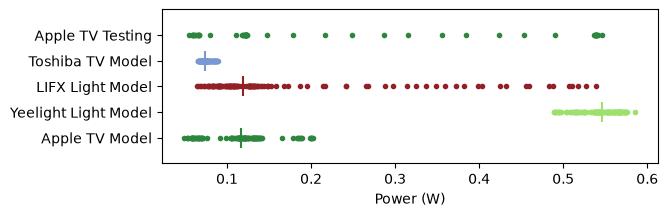

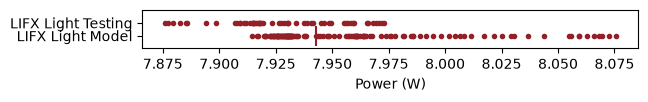

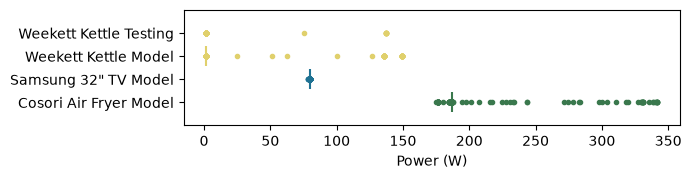

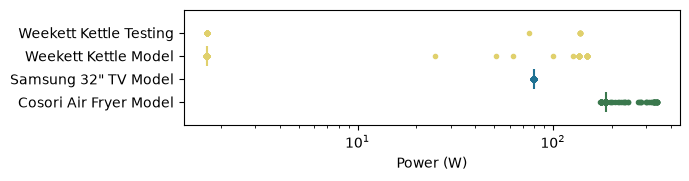

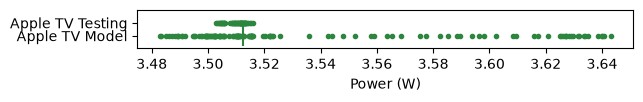

In [ ]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.

# 1 function to actually plot it

def plot_metrics(exp: Experiment, data: list[tuple[str, Data]]=[], log_scale=False):
    """
    if no data specified plot it all
    otherwise data is specifed in the form of (str, Data)
    """
    if len(exp.metrics) > 1:
        raise ValueError

    fig, ax = plt.subplots()

    if confused_with:
        for
        devices = list(exp.classes[main_device].keys())
    else:
        data = exp.data
        # 

    for datum in data:
        training = compute_profile(exp, datum.training)
        if datum.device in show_testing
    if device_name:
        main_device = [
            device for device in exp.devices if device.dir_name == device_name
        ][0]
        main_data = [data for data in exp.data if data.device.dir_name == device_name][
            0
        ]
        
        if main_device not in devices:
            devices = [main_device] + devices

        # testing = compute_profile(exp, main_data.testing)
        # for point in testing:
        #     ax.scatter(
        #         point[exp.metrics[0]], len(devices), c=main_device.colour, marker="."
        #     )
    else:
        devices = exp.devices
    indexes = [exp.devices.index(device) for device in devices]
    n = len(devices)

    for i, (index, device) in enumerate(zip(indexes, devices)):
        data = exp.data[index]

        # plot the training
        points = []
        for point in training:
            actual_point = point[exp.metrics[0]]
            ax.scatter(actual_point, n - i - 1, c=device.colour, marker=".")
            points.append(actual_point)
        ax.scatter(np.median(points), n - i - 1, marker="|", s=200, c=device.colour)

        # ax.scatter(point, 1, marker=".")
    if log_scale:
        ax.set_xscale("log")

    ax.set_ylim((-1, n + 1))
    ax.set_yticks(
        range(n + 1),
        labels=[f"{device.name()} {"Model"}" for device in devices[::-1]]
        + [f"{main_device.name()} Testing"],
    )

    ax.set_xlabel("Power (W)")
    fig.set_figheight(n / 2)


plot_confusion(idle, "lifx")
plot_confusion(idle, "weekett")
plot_confusion(idle, "appletv")
plot_confusion(active, "lifx")
plot_confusion(active, "weekett")
plot_confusion(active, "weekett", log_scale=True)
plot_confusion(active, "appletv")
plot_confusion(active, log_scale=True)
# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?
plt.show()

0.8974503963338297


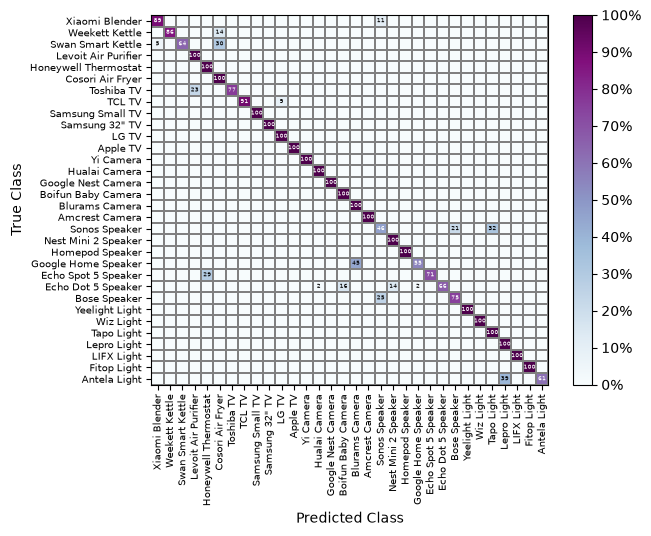

In [ ]:
# | label: mu sigma

mu_sigma = Experiment(
    c,
    State.ACTIVE,
    [Metric.MEAN, Metric.STD],
    180,
    10,
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)